# SPX：條件一致性 loss，lambda = 0.1

比較同為無 mixup 的兩組模型：上一輪 lambda=0，與本輪 lambda=0.1。
本輪重新執行 AR 500 步、diffusion 2,000 步；相同資料、seed 2024、七組條件、每組 200 條路徑。
對照沿用已完成的 `crash_20260929` 結果，不重訓、不重採樣；尚未加入 CFG。

Loss 定義：`L = L_diffusion + 0.1 * L_return + 0.1 * L_volatility`。
先把模型輸出（預設 v）換算為乾淨路徑 x0_hat，反標準化 close log return，
逐路徑計算 21 日累積報酬與年化樣本標準差；各自除以訓練標記的標準差後計算 MSE。
兩項 loss 相加，沒有再除以 2；訓練時點沿用均勻抽樣，沒有額外 annealing 或 t 權重。

預測乾淨路徑來自真實樣本加噪後的單步還原，並非完整生成。
因此仍以完整採樣的驗證條件誤差選 checkpoint，各組最佳步數可以不同。
真實未來沒有混入條件，AR 固定，scaler 僅由訓練資料估計。
這是單一歷史窗口、單一 seed 的條件符合度實驗，不代表完整市場分布或 RL 績效。


## 1. 執行與資料來源

`python3 scripts/run_spx_consistency.py` 會訓練、取樣並執行本 notebook。
結果預設位於 `outputs/spx/condition_lambda_0p1/`，另存每階段 log 與 pipeline_timings.json。
重跑請用新的 `--tag`；手動執行 notebook 可設定環境變數 SPX_CONSISTENCY_RUN 或修改 RUN_DIR。

命中要求同一條路徑的報酬誤差 ≤2 個百分點，年化波動率誤差 ≤5 個百分點。
這兩個條件不構成完整分布定義，不假設生成統計量必須符合常態分布。


In [1]:
from pathlib import Path
import json
import os
import hashlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
from matplotlib.patches import Rectangle
from IPython.display import display, Markdown

ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / 'spx_experiment.py').is_file()), None)
if ROOT is None:
    raise FileNotFoundError('請從 TimeDiff 或其子目錄啟動 notebook')
RUN_DIR = Path(os.environ.get('SPX_CONSISTENCY_RUN', ROOT/'outputs/spx/condition_lambda_0p1')).resolve()
RUNS = {
    'Lambda 0': {'train': ROOT/'outputs/spx/crash_20260929/train', 'samples': ROOT/'outputs/spx/crash_20260929/no_mixup_samples'},
    'Lambda 0.1': {'train': RUN_DIR/'train', 'samples': RUN_DIR/'samples'},
}
COLORS = {'Lambda 0': '#376C9E', 'Lambda 0.1': '#C47C28'}
STYLES = {'Lambda 0': '--', 'Lambda 0.1': '-'}
EXPORT = RUN_DIR / 'comparison'
EXPORT.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({'figure.dpi': 110, 'font.size': 10, 'axes.spines.top': False,
                     'axes.spines.right': False, 'axes.grid': True, 'grid.alpha': 0.18})

loaded = {}
for label, locations in RUNS.items():
    required = [locations['train']/name for name in ['metadata.json', 'training.csv']]
    required += [locations['samples']/name for name in
                 ['sampling.json', 'paths.csv', 'path_metrics.csv', 'summary.csv', 'history_features.csv']]
    missing = [str(p) for p in required if not p.is_file()]
    if missing:
        raise FileNotFoundError('先完成該組 train/sample：' + ', '.join(missing))
    loaded[label] = {
        'meta': json.loads((locations['train']/'metadata.json').read_text()),
        'sampling': json.loads((locations['samples']/'sampling.json').read_text()),
        'training': pd.read_csv(locations['train']/'training.csv'),
        'paths': pd.read_csv(locations['samples']/'paths.csv'),
        'saved_metrics': pd.read_csv(locations['samples']/'path_metrics.csv'),
        'saved_summary': pd.read_csv(locations['samples']/'summary.csv'),
        'history': pd.read_csv(locations['samples']/'history_features.csv'),
    }


## 2. 比較設定核對

兩組必須有相同資料指紋、切分、scaler、模型設定、seed、歷史窗口與目標條件。
容許條件一致性 loss 權重及其 scaler 設定不同；兩組都必須停用 mixup。


In [2]:
base, new = loaded['Lambda 0'], loaded['Lambda 0.1']
for key in ['data_sha256', 'train_end', 'val_end', 'seed', 'ar_steps',
            'feature_scaler', 'condition_scaler', 'split_windows']:
    assert base['meta'][key] == new['meta'][key], f'訓練設定不一致：{key}'
for key in ['lr', 'batch_size', 'ar_steps', 'steps', 'eval_every', 'val_batches', 'channels',
            'parameterization', 'sampler', 'no_market_condition', 'future_mixup', 'threads']:
    assert base['meta']['training_config'][key] == new['meta']['training_config'][key], f'訓練 CLI 不一致：{key}'
for key, value in base['meta']['args'].items():
    if key not in {'use_future_mixup', 'device', 'lambda_condition', 'condition_feature_scaler', 'condition_label_scaler'}:
        assert value == new['meta']['args'][key], f'模型設定不一致：{key}'
assert base['meta']['args']['use_future_mixup'] is False
assert base['meta']['args'].get('lambda_condition', 0.) == 0.
assert new['meta']['args']['lambda_condition'] == .1
assert new['meta']['args']['use_future_mixup'] is False
for key in ['history_end', 'seed', 'n_paths', 'conditions', 'return_tolerance', 'volatility_tolerance']:
    assert base['sampling'][key] == new['sampling'][key], f'取樣設定不一致：{key}'
pd.testing.assert_frame_equal(base['history'], new['history'])
np.testing.assert_array_equal(base['training']['step'], new['training']['step'])
assert base['training']['step'].max() == new['training']['step'].max() == 2000
price_path = ROOT / 'datasets/spx/prices.csv'
if price_path.exists():
    assert hashlib.sha256(price_path.read_bytes()).hexdigest() == new['meta']['data_sha256']

targets = np.asarray(new['sampling']['conditions'])
TOL_R = new['sampling']['return_tolerance']
TOL_V = new['sampling']['volatility_tolerance']
provenance = pd.DataFrame([{
    'method': label, 'lambda': d['meta']['args'].get('lambda_condition', 0.),
    'best_step': d['meta']['best_step'],
    'validation_condition_mse': d['meta']['best_validation_condition_mse'],
    'train_seed': d['meta']['seed'], 'sampling_seed': d['sampling']['seed'],
    'history_end': d['sampling']['history_end'], 'paths_per_condition': d['sampling']['n_paths'],
    'code_commit': d['meta'].get('code_commit', '未記錄（舊版）'),
} for label, d in loaded.items()])
display(provenance)


,method,lambda,best_step,validation_condition_mse,train_seed,sampling_seed,history_end,paths_per_condition,code_commit
0,Lambda 0,0.0,900,0.485747,2024,2024,2023-12-29,200,30bbb731131cc1cbaa9c7cc87130f767e24c0ffa
1,Lambda 0.1,0.1,2000,0.332294,2024,2024,2023-12-29,200,e6f2c4b53596d4933bec5a53c888ffa633eb0658


## 3. 由原始路徑重算指標

使用 21 個每日 log return，包含歷史最後收盤到第一個生成日的報酬：

- 累積報酬：`expm1(sum(rclose))`。
- 年化波動率：`std(rclose, ddof=1) * sqrt(252)`。
- MAE：每條路徑與指定條件的絕對差，再跨路徑平均。

先重算每條路徑，再核對已儲存的 metrics 與 summary。沒有先平均價格路徑才計算波動率。
5%–95% 是生成樣本的分位數區間，不是平均值的信賴區間。

In [3]:
metric_frames, rows = [], []
for label, data in loaded.items():
    paths = data['paths'].sort_values(['scenario', 'path', 'step'])
    assert not paths.duplicated(['scenario', 'path', 'step']).any()
    assert np.isfinite(paths.select_dtypes('number')).all().all()
    assert (paths.low <= paths.close).all() and (paths.close <= paths.high).all()
    groups = paths.groupby(['scenario', 'path'], sort=True)
    assert groups.size().eq(21).all()
    assert groups['step'].apply(lambda x: np.array_equal(x, np.arange(1, 22))).all()
    stats = groups['rclose'].agg(
        actual_return=lambda r: np.expm1(r.sum()),
        actual_volatility=lambda r: r.std(ddof=1)*np.sqrt(252),
    ).reset_index()
    saved = data['saved_metrics'].sort_values(['scenario', 'path']).reset_index(drop=True)
    np.testing.assert_array_equal(stats[['scenario', 'path']], saved[['scenario', 'path']])
    np.testing.assert_allclose(stats[['actual_return', 'actual_volatility']],
                               saved[['return', 'volatility']], rtol=1e-5, atol=1e-7)
    stats['method'] = label
    stats['target_return'] = targets[stats.scenario.to_numpy(), 0]
    stats['target_volatility'] = targets[stats.scenario.to_numpy(), 1]
    stats['return_error'] = stats.actual_return - stats.target_return
    stats['volatility_error'] = stats.actual_volatility - stats.target_volatility
    stats['hit'] = (stats.return_error.abs() <= TOL_R) & (stats.volatility_error.abs() <= TOL_V)
    np.testing.assert_array_equal(stats['hit'], saved['hit'])
    metric_frames.append(stats)
    for scenario, g in stats.groupby('scenario'):
        p = paths[paths.scenario == scenario]
        assert len(g) == data['sampling']['n_paths']
        np.testing.assert_allclose(p[['target_return', 'target_volatility']],
                                   np.tile(targets[scenario], (len(p), 1)))
        row = dict(method=label, scenario=scenario, n=len(g),
                   target_return=targets[scenario, 0], target_volatility=targets[scenario, 1],
                   return_mean=g.actual_return.mean(), volatility_mean=g.actual_volatility.mean(),
                   return_mae=g.return_error.abs().mean(), volatility_mae=g.volatility_error.abs().mean(),
                   return_p05=g.actual_return.quantile(.05), return_p95=g.actual_return.quantile(.95),
                   volatility_p05=g.actual_volatility.quantile(.05), volatility_p95=g.actual_volatility.quantile(.95),
                   joint_hit_rate=g.hit.mean(), rhigh_clip_rate=(p.rhigh_raw < 0).mean(),
                   rlow_clip_rate=(p.rlow_raw > 0).mean())
        saved_row = data['saved_summary'].set_index('scenario').loc[scenario]
        for key in row.keys() - {'method', 'scenario', 'n'}:
            np.testing.assert_allclose(row[key], saved_row[key], rtol=1e-5, atol=1e-7)
        rows.append(row)
metrics = pd.concat(metric_frames, ignore_index=True)
summary = pd.DataFrame(rows).sort_values(['scenario', 'method'])
summary.to_csv(EXPORT/'comparison_summary.csv', index=False)
cols = ['method', 'scenario', 'n', 'target_return', 'target_volatility', 'return_mean',
        'volatility_mean', 'return_mae', 'volatility_mae', 'joint_hit_rate', 'rhigh_clip_rate', 'rlow_clip_rate']
display(summary[cols].style.format({k: '{:.2%}' for k in cols if k not in {'method', 'scenario', 'n'}}))


,method,scenario,n,target_return,target_volatility,return_mean,volatility_mean,return_mae,volatility_mae,joint_hit_rate,rhigh_clip_rate,rlow_clip_rate
0,Lambda 0,0,200,-5.00%,15.00%,-4.34%,14.89%,2.78%,1.74%,42.50%,8.88%,15.52%
7,Lambda 0.1,0,200,-5.00%,15.00%,-4.35%,16.03%,2.13%,1.89%,53.50%,9.14%,12.74%
1,Lambda 0,1,200,5.00%,15.00%,2.64%,14.23%,3.64%,1.79%,28.50%,15.21%,10.71%
8,Lambda 0.1,1,200,5.00%,15.00%,4.36%,15.42%,2.32%,1.77%,49.50%,18.19%,9.69%
2,Lambda 0,2,200,-5.00%,35.00%,-4.74%,28.76%,3.98%,6.37%,14.50%,7.86%,12.57%
9,Lambda 0.1,2,200,-5.00%,35.00%,-4.89%,34.32%,3.27%,2.87%,32.00%,14.88%,13.26%
3,Lambda 0,3,200,5.00%,35.00%,4.33%,26.25%,4.43%,8.75%,5.50%,8.62%,8.48%
10,Lambda 0.1,3,200,5.00%,35.00%,3.68%,32.82%,3.60%,3.27%,24.50%,18.67%,11.05%
4,Lambda 0,4,200,-10.00%,40.00%,-10.26%,35.37%,4.06%,5.35%,18.00%,7.81%,14.36%
11,Lambda 0.1,4,200,-10.00%,40.00%,-10.28%,39.68%,3.40%,3.10%,26.00%,12.71%,13.71%


## 4. 各條件的統計量分布

每列一個指定條件，兩組使用同一組 bins；每欄共用尺度，避免視覺上誇大差異。
黑色虛線是目標，灰色區域是容許誤差。柱形顯示實際路徑數，不假設分布形狀。

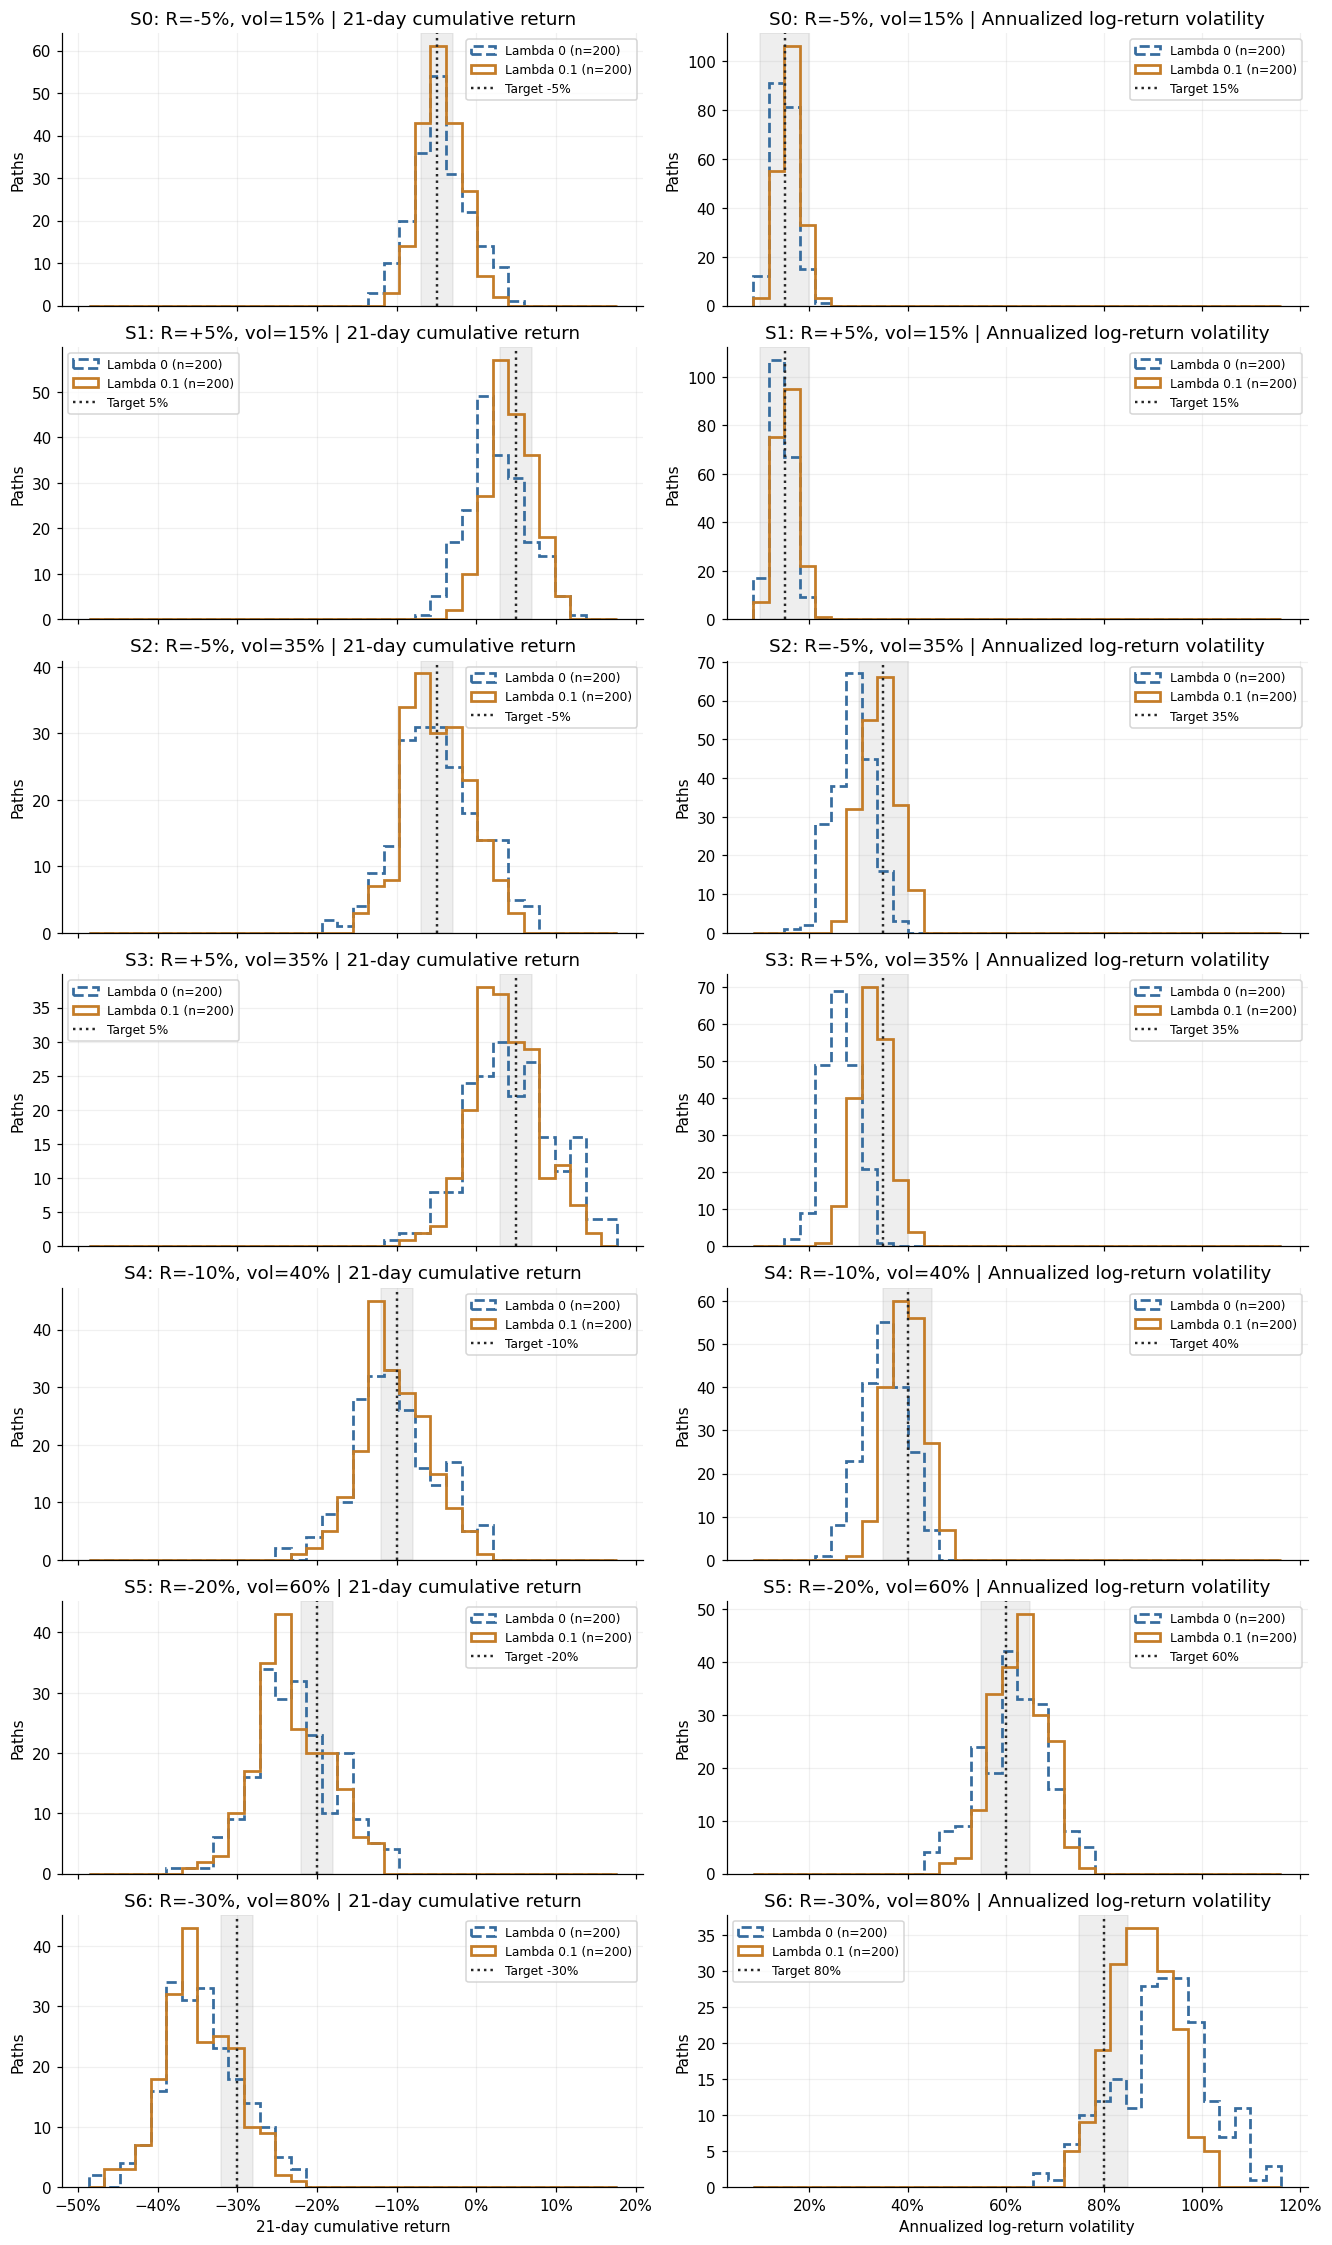

In [4]:
fig, axes = plt.subplots(len(targets), 2, figsize=(12, 2.9*len(targets)), sharex='col', constrained_layout=True)
for j, (metric, tolerance, title) in enumerate([
    ('actual_return', TOL_R, '21-day cumulative return'),
    ('actual_volatility', TOL_V, 'Annualized log-return volatility'),
]):
    lower = min(metrics[metric].min(), (targets[:, j]-tolerance).min())
    upper = max(metrics[metric].max(), (targets[:, j]+tolerance).max())
    bins = np.linspace(lower-.01, upper+.01, 35)
    for scenario in range(len(targets)):
        ax = axes[scenario, j]
        target = targets[scenario, j]
        ax.axvspan(target-tolerance, target+tolerance, color='#777777', alpha=.12)
        for label in RUNS:
            values = metrics.loc[(metrics.method == label) & (metrics.scenario == scenario), metric]
            ax.hist(values, bins=bins, histtype='step', linewidth=1.8,
                    color=COLORS[label], linestyle=STYLES[label], label=f'{label} (n={len(values)})')
        ax.axvline(target, color='#252525', linestyle=':', linewidth=1.6, label=f'Target {target:.0%}')
        ax.set_title(f'S{scenario}: R={targets[scenario, 0]:+.0%}, vol={targets[scenario, 1]:.0%} | {title}')
        ax.set_ylabel('Paths')
        ax.xaxis.set_major_formatter(PercentFormatter(1))
        ax.legend(fontsize=8)
        if scenario == len(targets)-1:
            ax.set_xlabel(title)
fig.savefig(EXPORT/'condition_histograms.png', dpi=150)
plt.show()


## 5. 聯合符合度

報酬與波動率必須在同一條路徑同時符合目標。十字是指定條件，灰色矩形是聯合命中範圍。
各子圖共用座標尺度；單獨看兩個邊際平均值可能掩蓋未命中的路徑。

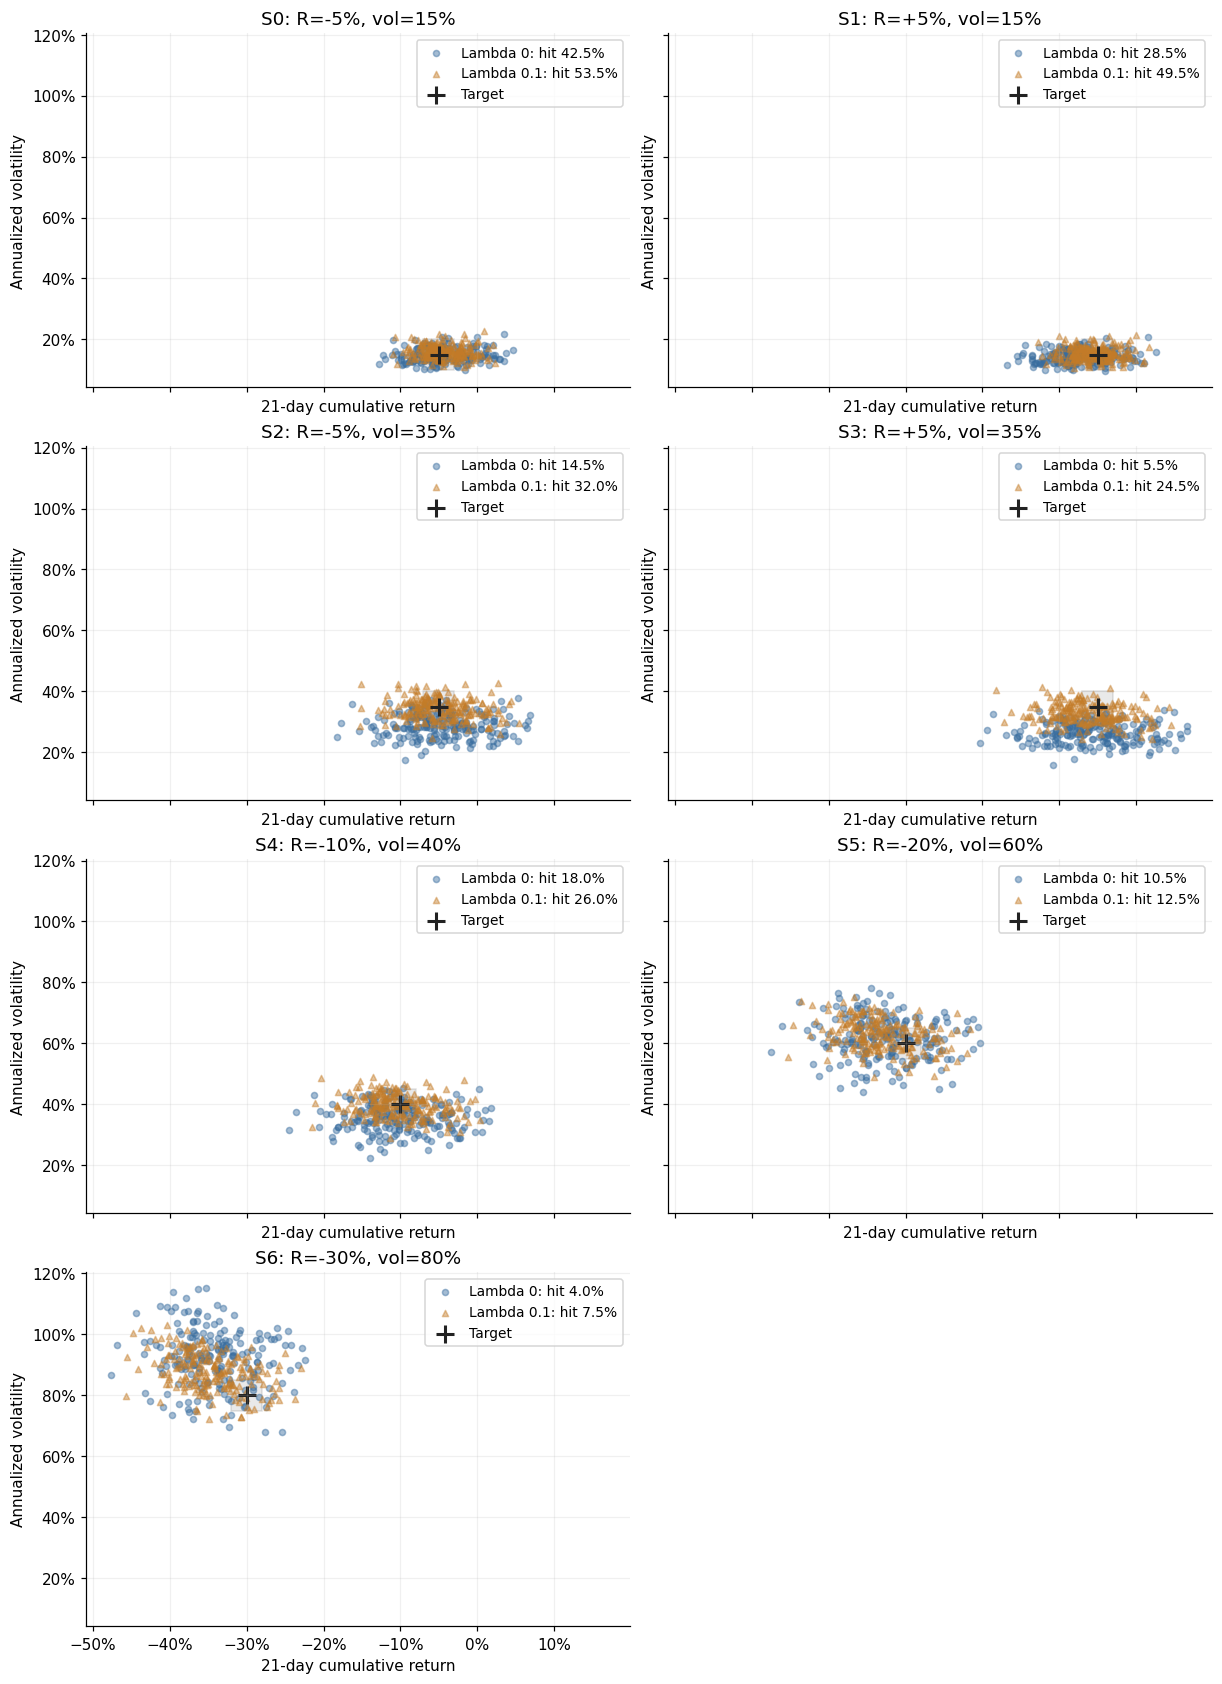

In [5]:
fig, axes = plt.subplots((len(targets)+1)//2, 2, figsize=(11, 3.8*((len(targets)+1)//2)), sharex=True, sharey=True, constrained_layout=True)
for scenario, ax in enumerate(axes.flat):
    if scenario >= len(targets):
        ax.set_visible(False)
        continue
    r, v = targets[scenario]
    ax.add_patch(Rectangle((r-TOL_R, v-TOL_V), 2*TOL_R, 2*TOL_V,
                           facecolor='#777777', edgecolor='#555555', alpha=.16))
    for label, marker in [('Lambda 0', 'o'), ('Lambda 0.1', '^')]:
        g = metrics[(metrics.method == label) & (metrics.scenario == scenario)]
        ax.scatter(g.actual_return, g.actual_volatility, color=COLORS[label], marker=marker,
                   s=16, alpha=.45, label=f'{label}: hit {g.hit.mean():.1%}')
    ax.scatter([r], [v], color='#222222', marker='+', s=150, linewidths=2, label='Target')
    ax.set_title(f'S{scenario}: R={r:+.0%}, vol={v:.0%}')
    ax.set_xlabel('21-day cumulative return')
    ax.set_ylabel('Annualized volatility')
    ax.xaxis.set_major_formatter(PercentFormatter(1))
    ax.yaxis.set_major_formatter(PercentFormatter(1))
    ax.legend(fontsize=9)
fig.savefig(EXPORT/'joint_conditions.png', dpi=150)
plt.show()


## 6. 訓練與驗證

左圖只比較 diffusion loss，不把新增的條件懲罰混入對照。右圖仍是完整採樣的驗證條件誤差。
記錄的是當下 batch，不是 epoch 平均；兩組依相同驗證規則各自挑選 checkpoint。


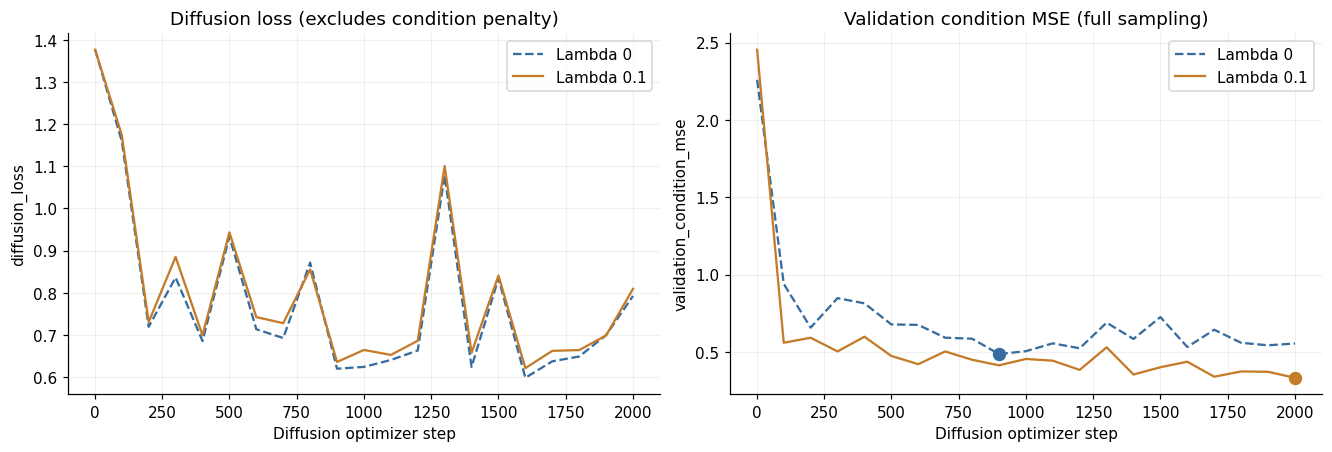

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), constrained_layout=True)
for label, data in loaded.items():
    log = data['training']
    for ax, column in zip(axes, ['train_loss', 'validation_condition_mse']):
        values = log['diffusion_loss'] if column == 'train_loss' and 'diffusion_loss' in log else log[column]
        ax.plot(log.step, values, color=COLORS[label], linestyle=STYLES[label], label=label)
        ax.set_xlabel('Diffusion optimizer step')
        ax.set_ylabel('diffusion_loss' if column == 'train_loss' else column)
        ax.legend()
    best = data['meta']['best_step']
    score = data['meta']['best_validation_condition_mse']
    axes[1].scatter([best], [score], color=COLORS[label], s=60, zorder=5)
axes[0].set_title('Diffusion loss (excludes condition penalty)')
axes[1].set_title('Validation condition MSE (full sampling)')
fig.savefig(EXPORT/'training_curves.png', dpi=150)
plt.show()


## 7. 路徑樣貌與限制

每組只畫編號 0–9 的路徑，避免挑選看起來較好的樣本。起點指數設為 100；虛線終點為指定累積報酬。
此圖只協助觀察形狀，不能取代尾端、波動聚集、回撤等市場真實性檢查。
OHLC 符號修正比例已列於上表：修正後價格合法不等於原始生成品質合格。

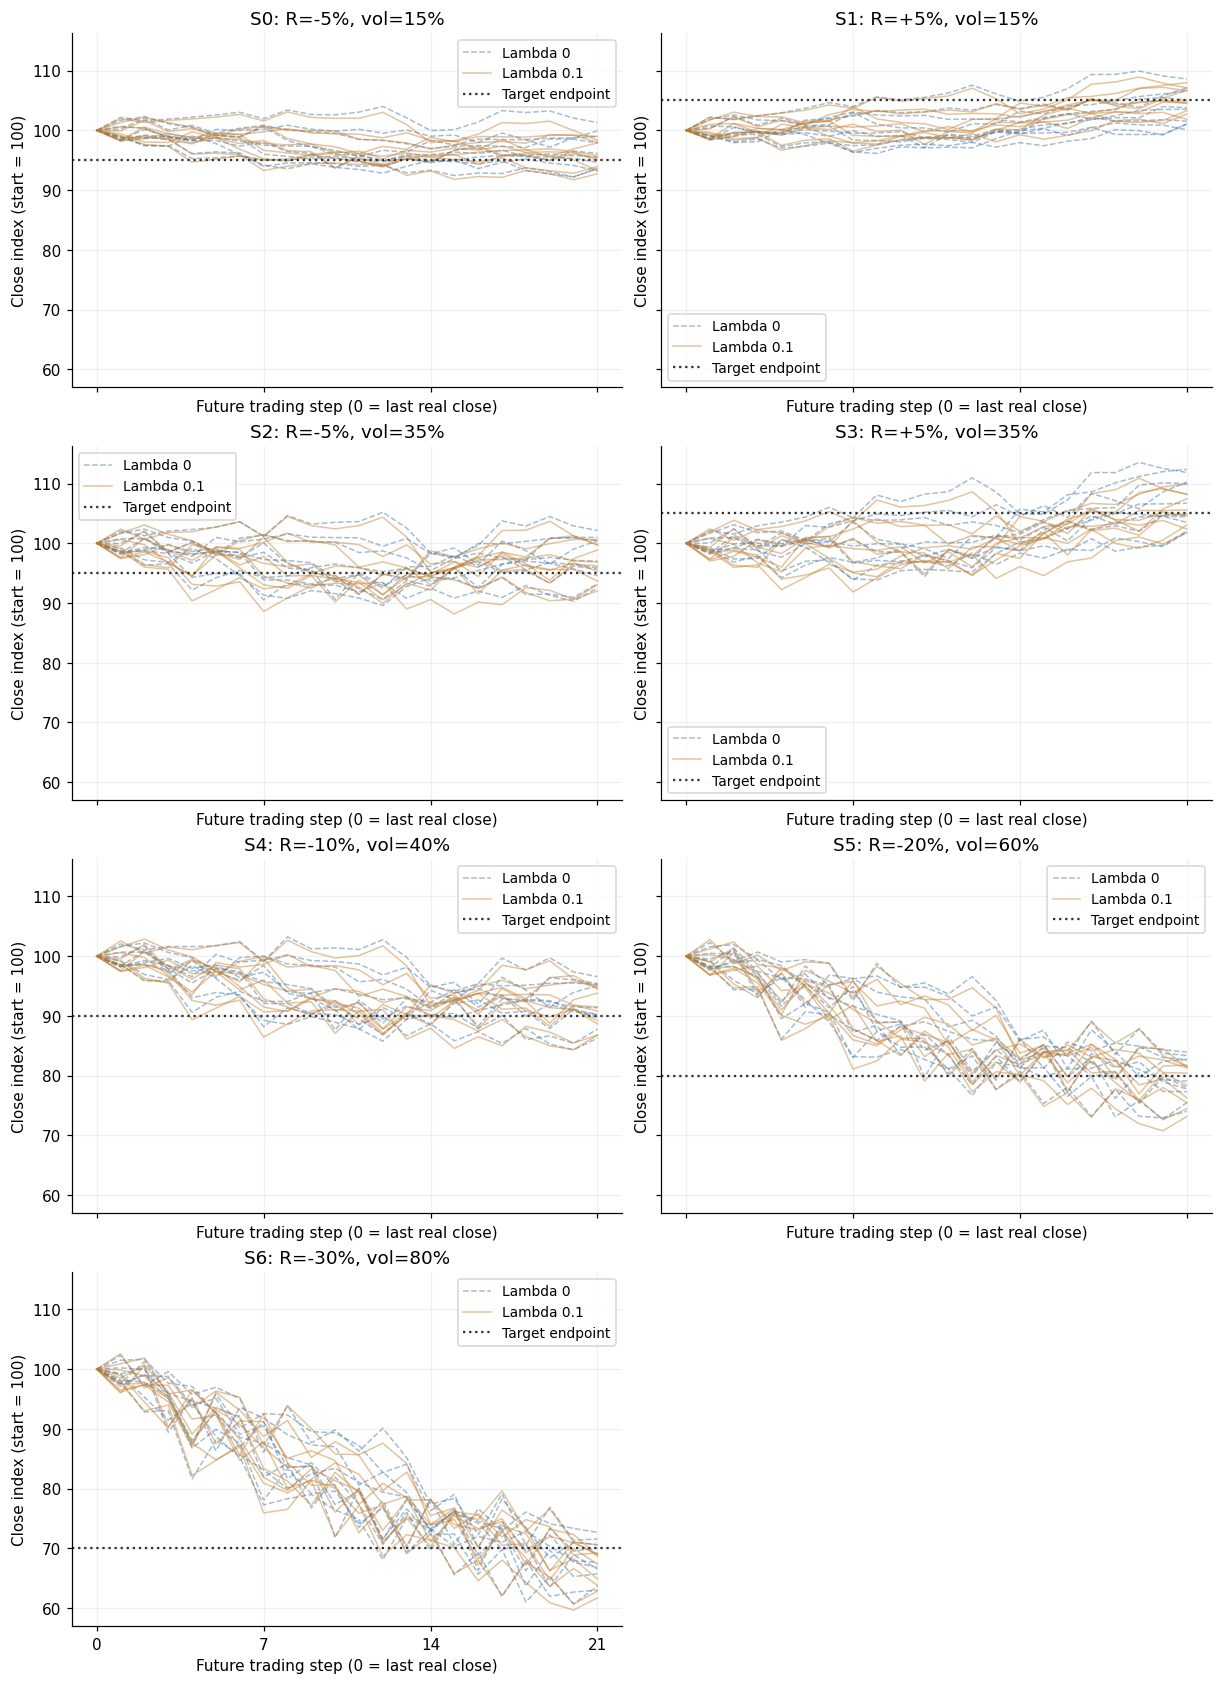

In [7]:
fig, axes = plt.subplots((len(targets)+1)//2, 2, figsize=(11, 3.8*((len(targets)+1)//2)), sharex=True, sharey=True, constrained_layout=True)
for scenario, ax in enumerate(axes.flat):
    if scenario >= len(targets):
        ax.set_visible(False)
        continue
    for label, data in loaded.items():
        paths = data['paths']
        for path_id in range(min(10, data['sampling']['n_paths'])):
            r = paths[(paths.scenario == scenario) & (paths.path == path_id)].sort_values('step').rclose.to_numpy()
            indexed = np.r_[100., 100*np.exp(np.cumsum(r))]
            ax.plot(np.arange(22), indexed, color=COLORS[label], linestyle=STYLES[label],
                    alpha=.45, linewidth=1, label=label if path_id == 0 else None)
    ax.axhline(100*(1+targets[scenario, 0]), color='#333333', linestyle=':', label='Target endpoint')
    ax.set_title(f'S{scenario}: R={targets[scenario, 0]:+.0%}, vol={targets[scenario, 1]:.0%}')
    ax.set_xlabel('Future trading step (0 = last real close)')
    ax.set_ylabel('Close index (start = 100)')
    ax.set_xticks([0, 7, 14, 21])
    ax.legend(fontsize=9)
fig.savefig(EXPORT/'example_paths.png', dpi=150)
plt.show()


## 8. 本輪結果摘要

以下差值為「Lambda 0.1 − Lambda 0」。MAE 差值小於零代表誤差降低；命中率差值大於零代表提升。
報酬與波動率的差值單位均為百分點（pp）。此處不把 1,400 條路徑當成 1,400 次獨立模型訓練，亦不宣稱統計顯著。

In [8]:
before = summary[summary.method == 'Lambda 0'].set_index('scenario')
after = summary[summary.method == 'Lambda 0.1'].set_index('scenario')
comparison = after[['target_return', 'target_volatility']].copy()
for metric in ['return_mae', 'volatility_mae', 'joint_hit_rate']:
    comparison[metric + '_delta_pp'] = 100*(after[metric]-before[metric])
display(comparison.style.format({'target_return': '{:+.0%}', 'target_volatility': '{:.0%}',
    **{k: '{:+.2f}' for k in comparison if k.endswith('_pp')}}))
overall = summary.groupby('method')[['return_mae', 'volatility_mae', 'joint_hit_rate']].mean()
display(overall.style.format('{:.2%}'))
improved_r = int((comparison.return_mae_delta_pp < 0).sum())
improved_v = int((comparison.volatility_mae_delta_pp < 0).sum())
display(Markdown(f'本輪 {len(targets)} 組條件中，報酬 MAE 降低 **{improved_r} 組**，'
                 f'波動率 MAE 降低 **{improved_v} 組**。各條件樣本數相同，上表為等權平均。'
                 '是否值得繼續採用，仍需同時檢查命中率、路徑多樣性與 OHLC 修正比例。'))
comparison.to_csv(EXPORT/'comparison_deltas.csv')
print('圖表與彙整表：', EXPORT)


圖表與彙整表： /Users/chuanwei/Files/Projects/nycu_fintech/TimeDiff/outputs/spx/condition_lambda_0p1/comparison


,target_return,target_volatility,return_mae_delta_pp,volatility_mae_delta_pp,joint_hit_rate_delta_pp
scenario,,,,,
0,-5%,15%,-0.64,+0.15,+11.00
1,+5%,15%,-1.33,-0.02,+21.00
2,-5%,35%,-0.72,-3.50,+17.50
3,+5%,35%,-0.82,-5.48,+19.00
4,-10%,40%,-0.66,-2.26,+8.00
5,-20%,60%,-0.21,-0.93,+2.00
6,-30%,80%,+0.05,-4.61,+3.50


,return_mae,volatility_mae,joint_hit_rate
method,,,
Lambda 0,4.16%,6.11%,17.64%
Lambda 0.1,3.54%,3.74%,29.36%


本輪 7 組條件中，報酬 MAE 降低 **6 組**，波動率 MAE 降低 **6 組**。各條件樣本數相同，上表為等權平均。是否值得繼續採用，仍需同時檢查命中率、路徑多樣性與 OHLC 修正比例。

## 9. 極端條件的歷史支持

以下只使用訓練窗口。列出目標在訓練條件二維標準化空間的最近距離，以及同一命中容許區間內的窗口數。
窗口彼此重疊，不能把窗口數當成獨立事件數。區間內有歷史樣本也不保證在目前歷史背景下合理；
零窗口代表這個局部區域沒有訓練觀測，不表示數學上不可能。報酬與波動率同步調整，無法單獨識別兩個條件的作用。


In [9]:
support = pd.read_csv(RUNS['Lambda 0.1']['train']/'train_conditions.csv')
scaler = new['meta']['condition_scaler']
mean, scale = np.array(scaler['mean']), np.array(scaler['scale'])
raw = support[['return', 'volatility']].to_numpy()
checks = []
for scenario, target in enumerate(targets):
    distance = np.linalg.norm((raw-target)/scale, axis=1)
    nearest = raw[distance.argmin()]
    inside = (np.abs(raw[:, 0]-target[0]) <= TOL_R) & (np.abs(raw[:, 1]-target[1]) <= TOL_V)
    checks.append(dict(scenario=scenario, target_return=target[0], target_volatility=target[1],
                       nearby_train_windows=int(inside.sum()), nearest_distance_z=distance.min(),
                       nearest_return=nearest[0], nearest_volatility=nearest[1]))
support_check = pd.DataFrame(checks)
support_check.to_csv(EXPORT/'training_support.csv', index=False)
display(support_check.style.format({k:'{:.1%}' for k in
    ['target_return','target_volatility','nearest_return','nearest_volatility']}))
display(support.agg(['min','max']).style.format('{:.1%}'))
# Compare the original four and newly added crash conditions separately.
by_group = summary.assign(group=np.where(summary.scenario < 4, 'Original four', 'Crash three'))
display(by_group.groupby(['group','method'])[['return_mae','volatility_mae','joint_hit_rate']].mean().style.format('{:.2%}'))


,scenario,target_return,target_volatility,nearby_train_windows,nearest_distance_z,nearest_return,nearest_volatility
0,0,-5.0%,15.0%,324,0.024725,-5.1%,15.0%
1,1,5.0%,15.0%,648,0.005797,5.0%,15.0%
2,2,-5.0%,35.0%,47,0.067117,-5.1%,35.7%
3,3,5.0%,35.0%,22,0.011445,5.0%,34.9%
4,4,-10.0%,40.0%,21,0.248942,-9.5%,37.5%
5,5,-20.0%,60.0%,2,0.193543,-19.6%,58.1%
6,6,-30.0%,80.0%,5,0.016507,-30.0%,80.2%


,return,volatility
min,-33.0%,3.5%
max,25.1%,97.6%


## 10. 新增 loss 與實際耗時

分別顯示兩項標準化條件 MSE，以及加權後總懲罰。
計時使用 wall clock，CPU 為本輪執行裝置；若使用 CUDA，計時邊界會同步 GPU。
訓練子階段互不重疊，`total_seconds` 是加總值，不能再與子階段重複相加。
訓練與取樣內部計時不含 Python 程序啟動／import；完整程序與 notebook 耗時由 pipeline_timings.json 記錄。


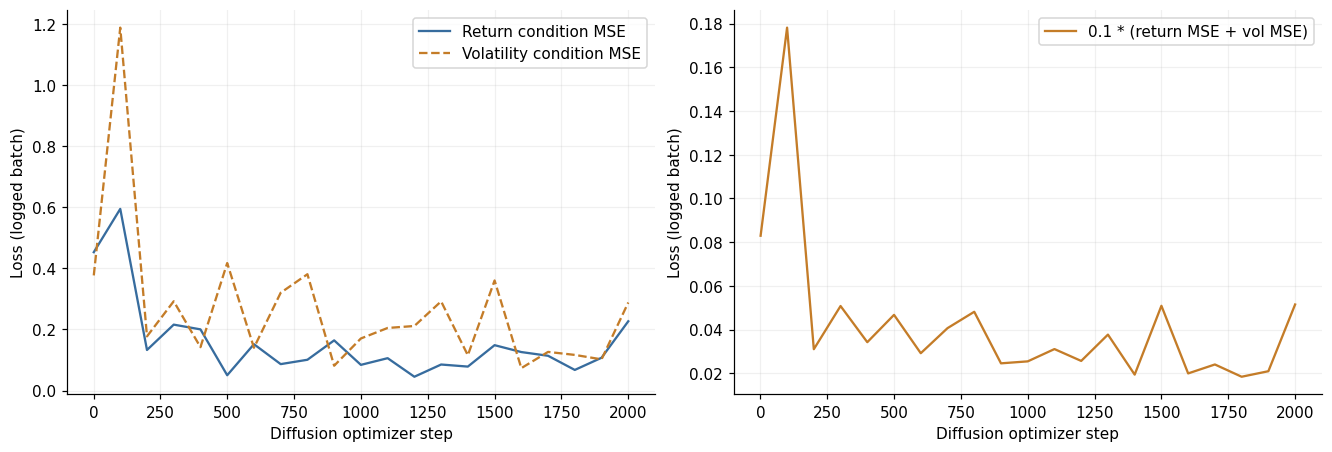

,stage,component,seconds
0,Training,data_model_setup_seconds,0.79
1,Training,ar_pretraining_seconds,0.49
2,Training,diffusion_update_seconds,233.65
3,Training,validation_seconds,137.04
4,Training,other_logging_checkpoint_seconds,0.92
5,Training,total_seconds,372.88
6,Sampling,generation_seconds,164.31
7,Sampling,setup_metrics_plot_export_seconds,2.95
8,Sampling,total_seconds,167.26


In [10]:
log = new['training']
fig, axes = plt.subplots(1, 2, figsize=(12, 4), constrained_layout=True)
axes[0].plot(log.step, log.return_condition_loss, label='Return condition MSE', color='#376C9E')
axes[0].plot(log.step, log.volatility_condition_loss, label='Volatility condition MSE', color='#C47C28', linestyle='--')
axes[1].plot(log.step, log.weighted_condition_loss, label='0.1 * (return MSE + vol MSE)', color='#C47C28')
for ax in axes:
    ax.set_xlabel('Diffusion optimizer step')
    ax.set_ylabel('Loss (logged batch)')
    ax.legend()
fig.savefig(EXPORT/'condition_loss_components.png', dpi=150)
plt.show()
timing_rows = []
for stage, folder in [('Training', RUN_DIR/'train'), ('Sampling', RUN_DIR/'samples')]:
    timing = json.loads((folder/'timings.json').read_text())
    timing_rows.extend({'stage':stage, 'component':k, 'seconds':v} for k,v in timing.items() if k.endswith('_seconds'))
timing_table = pd.DataFrame(timing_rows)
display(timing_table.style.format({'seconds':'{:.2f}'}))
timing_table.to_csv(EXPORT/'phase_timings.csv',index=False)


本輪只測試 lambda=0.1，未搜尋其他權重，尚未加入 CFG。
判讀時同時看逐路徑 MAE、命中率、條件平均偏差與 OHLC 修正比例；平均接近目標不表示每條路徑都準確。


## lambda=0.1 實跑結果與時間

本輪程式版本 `e6f2c4b`，CPU、2 threads；AR 500 步、diffusion 2,000 步。
選中第 2,000 步 checkpoint，驗證條件 MSE 0.332294（lambda=0 對照：0.485747）。
已核對 AR 權重與對照完全一致且訓練後未改變。19 項測試通過；
notebook 全部 10 格程式已以 IPython 同程序模式執行，原始路徑指標核對通過，5 張圖已檢視。

| 目標報酬 | 目標年化波動率 | lambda=0.1 平均報酬 | 平均波動率 | lambda=0 命中率 | lambda=0.1 命中率 |
|---:|---:|---:|---:|---:|---:|
| -5% | 15% | -4.35% | 16.03% | 42.5% | 53.5% |
| +5% | 15% | +4.36% | 15.42% | 28.5% | 49.5% |
| -5% | 35% | -4.89% | 34.32% | 14.5% | 32.0% |
| +5% | 35% | +3.68% | 32.82% | 5.5% | 24.5% |
| -10% | 40% | -10.28% | 39.68% | 18.0% | 26.0% |
| -20% | 60% | -23.15% | 62.88% | 10.5% | 12.5% |
| -30% | 80% | -34.72% | 87.71% | 4.0% | 7.5% |

七組等權平均：報酬 MAE 由 4.16 降至 3.54 個百分點，波動率 MAE 由 6.11 降至
3.74 個百分點，聯合命中率由 17.64% 提升至 29.36%。
原有四組命中率由 22.75% 至 39.88%；三組暴跌由 10.83% 至 15.33%。
命中仍採報酬 ±2 個百分點、年化波動率 ±5 個百分點，須在同一路徑同時滿足。

限制與未改善處：

- 七組命中率皆提高，但兩種 MAE 各只有 6/7 組下降。
- -30%／80% 的平均波動率從 91.95% 降到 87.71%，但平均報酬從 -34.25% 變成 -34.72%；報酬 MAE 由 5.40 增至 5.45 個百分點。
- -5%／15% 的波動率 MAE 從 1.74 增至 1.89 個百分點。
- high 特徵符號修正比例平均從 8.57% 升至 12.77%；low 從 13.24% 降至 11.62%。條件符合度提高不等於 OHLC 整體品質全面改善。
- 只有一個歷史窗口、seed 與 lambda，沒有 CFG、沒有 RL 評估，也不能據此認定最佳權重。

### 各階段實測耗時

以下為本機 wall-clock；各細分列不重疊。保留資料與前次對照直接沿用，沒有重新下載或重訓對照。
完整程序與 Python 啟動時間另外列出，不能把程序總計和其子階段再次加總。

| 子階段 | 秒 |
|---|---:|
| 資料與模型準備 | 0.79 |
| AR 預訓 500 步 | 0.49 |
| Diffusion 更新 2,000 步 | 233.65 |
| 驗證 21 次 | 137.04 |
| 訓練記錄／checkpoint／其他迴圈開銷 | 0.92 |
| 訓練程序啟動／import／退出 | 2.93 |
| 七組生成，共 1,400 條 | 164.31 |
| 取樣準備／指標／繪圖／匯出 | 2.95 |
| 取樣程序啟動／import／退出 | 4.73 |
| Notebook 分析與圖表（含程序啟動） | 10.74 |
| 流程控制與計時檔寫入 | 0.01 |

完整訓練程序 **375.82 秒**，取樣程序 **171.99 秒**，notebook **10.74 秒**。
全流程 **558.55 秒（約 9 分 19 秒）**，不含程式開發、測試及完成後人工檢視時間。

計時來自本輪 `train/timings.json`、`samples/timings.json` 與 `pipeline_timings.json`；不是舊版本速度基準比較。
